# Mars terrain segmentation

AI4MARS Curiosity NavCam images are used to identify soil, bedrock, sand and large rock
at each pixel. The input is a grayscale image and the output is a terrain mask.

A Random Forest using pixel intensity and a 3x3 local mean is compared with a small
encoder-decoder CNN. The CNN currently has no skip connections and 106,516 parameters.

Data preparation started with 16,064 pairs. Excluding 163 all-unlabeled pairs and
both entries with conflicting annotations left 15,899 pairs. Following the TA's
feedback, each rover command sequence stays in one split before crops are made:
11,129 training, 2,385 validation and 2,385 internal-test pairs. Raw files stay unchanged.

CNN training uses 256x256 crops, horizontal flips and small brightness changes.
The image and mask flip together; brightness changes only the image. Validation is
not augmented. Models are compared using labeled-pixel accuracy, ignoring label 255. Rare classes,
especially large rock, may be hidden by the overall accuracy. Internal-test images
and the separate expert masks are not used here.

The starting settings are one epoch, batch size 8 and Adam at 0.001. These are agreed
starting choices, not tuned values. No hyperparameter search is included.

The current evaluation loads saved models without retraining. GPU use is automatic
when CUDA is available. Fixed seeds control random choices, but exact GPU results
can vary. The frozen split is reused and raw files remain unchanged.

For limited runtime, both models use one saved 100-image validation subset. It includes
the three saved forest examples plus a seeded sample from already-completed forest
validation images. This convenience subset may not represent all 2,385 validation
images. All reported subset scores and the bedrock reference use these same images.

## 1. Imports and settings

In [1]:
from pathlib import Path
import hashlib
import json
import pickle
import random
import shutil
import re

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import sklearn
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 360
TERRAIN_CLASSES = ("soil", "bedrock", "sand", "large_rock")
IGNORE_LABEL = 255
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.6.0+cu124 | device: cuda


Load the libraries, class labels and random seed needed by later cells. Use the GPU when available.

In [ ]:
PROJECT_DIRECTORY = Path.cwd()
if not (PROJECT_DIRECTORY / "data/raw/msl/ncam").is_dir():
    PROJECT_DIRECTORY = PROJECT_DIRECTORY / "Terrain Segmentation"
if not (PROJECT_DIRECTORY / "data/raw/msl/ncam").is_dir():
    raise FileNotFoundError("Set PROJECT_DIRECTORY to your project with the NavCam data")
PROJECT_DIRECTORY = PROJECT_DIRECTORY.resolve()
DATA_DIRECTORY = PROJECT_DIRECTORY / "data/raw/msl/ncam"
MANIFEST_PATH = PROJECT_DIRECTORY / "data/prepared_splits.json"

RUN_DATA_PREPARATION = False
RUN_RF_TRAINING = False
RUN_RF_VALIDATION = True
RUN_CNN_TRAINING = False
RUN_CNN_VALIDATION = True

VALIDATION_SIZE = 100
SUBSET_PATH = PROJECT_DIRECTORY / f'data/validation_subset_{VALIDATION_SIZE}.json'
PIXELS_PER_IMAGE = 100
BATCH_SIZE = 8
LEARNING_RATE = 0.001
EPOCHS = 1

# Existing runs are read-only inputs. Notebook-generated runs use separate folders.
RF_MODEL_TO_LOAD = PROJECT_DIRECTORY / "outputs/random_forest_run1/model.pkl"
CNN_MODEL_TO_LOAD = PROJECT_DIRECTORY / "outputs/cnn_run1/best.pt"
RF_OUTPUT = PROJECT_DIRECTORY / "outputs/notebook_rf_run1"
CNN_OUTPUT = PROJECT_DIRECTORY / "outputs/notebook_cnn_gpu_run1"
for output_folder in (RF_OUTPUT, CNN_OUTPUT):
    if output_folder.resolve().is_relative_to(PROJECT_DIRECTORY / "data"):
        raise ValueError("Experiment output folders must be outside data/")
if EPOCHS < 1 or BATCH_SIZE < 1 or PIXELS_PER_IMAGE < 1:
    raise ValueError("Epochs, batch size and pixels per image must be positive")
print("Project:", PROJECT_DIRECTORY)

Validate the saved models on the same fixed 100-image subset. Retraining is off; the full frozen splits stay unchanged.

## 2. Random Forest baseline

In [3]:
def pixel_features(image):
    """Represent each pixel by its grayscale intensity and a 3x3 local mean.

    Expect an image with pixel values from 0 to 255. Return an array shaped
    (height * width, 2), in row-major pixel order. Edge neighborhoods repeat
    the nearest image pixel, and both features are scaled to [0, 1].
    """
    image = np.asarray(image)
    if image.ndim != 2 or image.size == 0:
        raise ValueError("Expected a nonempty grayscale image")
    if not np.isfinite(image).all() or image.min() < 0 or image.max() > 255:
        raise ValueError("Expected finite image values between 0 and 255")

    intensity = image.astype(np.float32) / 255.0
    height, width = intensity.shape
    padded = np.pad(intensity, 1, mode="edge")
    neighborhood_sum = np.zeros_like(intensity)
    for row in range(3):
        for column in range(3):
            neighborhood_sum += padded[row:row + height, column:column + width]
    neighborhood_mean = neighborhood_sum / 9.0
    # Keep the two features together, then make one row per pixel.
    feature_image = np.stack([intensity, neighborhood_mean], axis=-1)
    features = feature_image.reshape(height * width, 2)
    return features

Represent each pixel with its intensity and a nearby average so the forest has two input features.

In [ ]:
def build_baseline(seed=360):
    """Use default model settings and a fixed seed for repeatability."""
    from sklearn.ensemble import RandomForestClassifier

    return RandomForestClassifier(random_state=seed)

Define the forest constructor with default settings and a fixed seed. Fitting happens in the training section.

## 3. Initial CNN

In [5]:
def convolution_block(input_channels, output_channels):
    """Learn spatial features without changing the height or width."""
    return nn.Sequential(
        nn.Conv2d(input_channels, output_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(output_channels, output_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )

Reuse the same convolution block to keep the CNN definition short and consistent.

In [6]:
class TerrainCNN(nn.Module):
    """A basic encoder-decoder; skip-connection comparisons come in a later step.

    Input: grayscale images shaped (batch, 1, height, width).
    Output: raw class scores shaped (batch, 4, height, width), ordered as
    soil, bedrock, sand, and large rock. No softmax is applied here.
    """

    def __init__(self):
        super().__init__()

        # Encoder: increase feature channels while reducing spatial resolution.
        self.encoder1 = convolution_block(1, 16)
        self.encoder2 = convolution_block(16, 32)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.bottleneck = convolution_block(32, 64)

        # Decoder: restore image resolution, then output four scores per pixel.
        self.decoder2 = convolution_block(64, 32)
        self.decoder1 = convolution_block(32, 16)
        self.classifier = nn.Conv2d(16, 4, kernel_size=1)

    def forward(self, image):
        first_features = self.encoder1(image)
        second_features = self.encoder2(self.pool(first_features))
        encoded = self.bottleneck(self.pool(second_features))

        decoded = F.interpolate(
            encoded,
            size=second_features.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        decoded = self.decoder2(decoded)

        decoded = F.interpolate(
            decoded,
            size=first_features.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        decoded = self.decoder1(decoded)
        return self.classifier(decoded)

Learn features at smaller resolutions, then restore the image size to produce four class scores per pixel.

In [7]:
cnn = TerrainCNN().to(device)
cnn.eval()
with torch.no_grad():
    dummy_scores = cnn(torch.zeros(1, 1, 256, 256, device=device))
assert tuple(dummy_scores.shape) == (1, 4, 256, 256)
assert torch.isfinite(dummy_scores).all()
print("Output shape:", tuple(dummy_scores.shape))
print("Trainable parameters:", sum(p.numel() for p in cnn.parameters()))
del dummy_scores

Output shape: (1, 4, 256, 256)
Trainable parameters: 106516


Check the output shape before using real data. The synthetic forward pass does not train the CNN.

## 4. Data preparation

In [8]:
def command_sequence(image_name):
    """Return the group ID that must stay together when splits are later made.

    Both camera eyes and consecutive frames from a command share this ID.
    An unknown filename is rejected rather than assigned a random group.
    """
    match = re.fullmatch(
        r"N[LR][AB]_\d{9}EDR_[A-Z]\d{7}([A-Z_]{4}\d{5})[A-Z_]\d\.JPG",
        image_name.upper(),
    )
    if match is None:
        raise ValueError(f"Unrecognized Curiosity NavCam filename: {image_name}")
    return "MSL:" + match.group(1)

Use command IDs to keep related frames in the same split and reduce data leakage.

In [9]:
def pixel_fingerprint(array):
    """Identify the pixel contents so changed or duplicate files can be caught."""
    contents = str(array.shape).encode() + array.tobytes()
    return hashlib.sha256(contents).hexdigest()

Identify duplicate or changed pixel contents with a fingerprint. This is a data check, not a model feature.

In [10]:
def read_pair(root, record):
    image_path = Path(root) / record["image"]
    mask_path = Path(root) / record["mask"]
    with Image.open(image_path) as source:
        image = np.array(source.convert("L"))
    with Image.open(mask_path) as source:
        mask = np.array(source)

    # Some masks store the same labels in three identical channels.
    if mask.ndim == 3 and np.all(mask == mask[..., :1]):
        mask = mask[..., 0]
    if mask.ndim != 2 or image.shape != mask.shape:
        raise ValueError("Image and mask dimensions do not match")
    if not np.isin(mask, [0, 1, 2, 3, IGNORE_LABEL]).all():
        raise ValueError("Unexpected label in mask")
    return image, mask

Check that each grayscale image matches its mask dimensions and that the labels are valid. Raw files remain unchanged.

In [11]:
def collect_samples(root):
    root = Path(root)
    images = {}
    for path in (root / "images/edr").iterdir():
        if path.is_file() and path.suffix.lower() in (".jpg", ".jpeg"):
            images[path.stem.upper()] = path

    mask_paths = sorted((root / "labels/train").glob("*.png"))
    if not mask_paths:
        raise FileNotFoundError("No training masks found")
    samples = []
    ignored_masks = []
    seen_images = {}
    for index, mask_path in enumerate(mask_paths, 1):
        image_name = mask_path.stem.removesuffix("_merged").upper()
        if image_name not in images:
            raise FileNotFoundError(f"No image for {mask_path.name}")
        image_path = images[image_name]
        record = {"image": image_path.relative_to(root).as_posix(),
                  "mask": mask_path.relative_to(root).as_posix(),
                  "sequence": command_sequence(image_path.name),
                  "review_required": False}
        image, mask = read_pair(root, record)
        if np.all(mask == IGNORE_LABEL):
            ignored_masks.append(record["mask"])
            continue
        if min(image.shape) < 256:
            raise ValueError("An image is smaller than a 256x256 crop")

        record["shape"] = list(image.shape)
        record["image_sha256"] = pixel_fingerprint(image)
        record["mask_sha256"] = pixel_fingerprint(mask)
        pixel_counts = np.bincount(mask.ravel(), minlength=256)
        record["pixel_counts"] = pixel_counts[[0, 1, 2, 3, IGNORE_LABEL]].tolist()

        # Flag both entries. Do not choose between their annotations.
        image_hash = record["image_sha256"]
        if image_hash in seen_images:
            first_index = seen_images[image_hash]
            samples[first_index]["review_required"] = True
            record["review_required"] = True
        else:
            seen_images[image_hash] = len(samples)
        samples.append(record)
        if index % 1000 == 0:
            print(f"Read {index}/{len(mask_paths)} pairs")
    return samples, ignored_masks

Match images and masks, skip all-unlabeled pairs and flag both copies of duplicate images. Keep all raw files.

In [12]:
def grouped_splits(records, fractions=(0.7, 0.15, 0.15), seed=360):
    """Allocate whole command groups, approximating target image counts."""
    if len(fractions) != 3 or min(fractions) <= 0 or not np.isclose(sum(fractions), 1):
        raise ValueError("Three positive split fractions must sum to one")
    groups = {}
    for record in records:
        sequence = record["sequence"]
        if sequence not in groups:
            groups[sequence] = []
        groups[sequence].append(record)
    if len(groups) < 3:
        raise ValueError("At least three independent sequence groups are required")
    names = list(sorted(groups))
    random.Random(seed).shuffle(names)
    # Place large groups first; shuffle supplies deterministic random tie breaks.
    names.sort(key=lambda name: len(groups[name]), reverse=True)
    split_names = ["train", "val", "test"]
    targets = [fraction * len(records) for fraction in fractions]
    counts = [0, 0, 0]
    assigned = []
    for name in names:
        # Choose the split furthest below its requested proportion.
        destination = 0
        largest_gap = (targets[0] - counts[0]) / targets[0]
        for i in range(1, 3):
            gap = (targets[i] - counts[i]) / targets[i]
            if gap > largest_gap:
                destination = i
                largest_gap = gap
        split = split_names[destination]
        for record in groups[name]:
            sample = record.copy()
            sample["split"] = split
            assigned.append(sample)
        counts[destination] += len(groups[name])
    if 0 in counts:
        raise ValueError("Group sizes prevent nonempty splits; review allocation")
    return sorted(assigned, key=lambda record: record["mask"])

Keep whole command groups together while approximating a 70/15/15 split. Preserve the existing allocation rule.

In [13]:
def create_manifest(root):
    samples, ignored_masks = collect_samples(root)
    usable = []
    pending = []
    for sample in samples:
        if sample["review_required"]:
            pending.append(sample)
        else:
            usable.append(sample)
    records = grouped_splits(usable, seed=SEED)

    summary = {}
    for split in ("train", "val", "test"):
        counts = np.zeros(5, dtype=np.int64)
        image_counts = np.zeros(4, dtype=np.int64)
        sequences = set()
        number_of_images = 0
        for record in records:
            if record["split"] != split:
                continue
            pixels = np.array(record["pixel_counts"])
            counts += pixels
            image_counts += pixels[:4] > 0
            sequences.add(record["sequence"])
            number_of_images += 1
        if np.any(counts[:4] == 0):
            raise ValueError(f"A terrain class is missing from {split}")

        class_pixels = {}
        class_images = {}
        class_fractions = {}
        for class_id, class_name in enumerate(TERRAIN_CLASSES):
            class_pixels[class_name] = int(counts[class_id])
            class_images[class_name] = int(image_counts[class_id])
            class_fractions[class_name] = float(counts[class_id] / counts[:4].sum())
        summary[split] = {"images": number_of_images, "sequences": len(sequences),
                          "pixels_by_class": class_pixels,
                          "images_containing_class": class_images,
                          "labeled_pixel_fractions": class_fractions,
                          "ignored_pixels": int(counts[4])}

    return {"dataset_root": "raw/msl/ncam", "seed": SEED,
            "crop_size": 256, "records": records, "summary": summary,
            "excluded_pending_review": pending,
            "excluded_all_unlabeled_pairs": len(ignored_masks),
            "excluded_masks": ignored_masks}

Exclude flagged annotations and save split membership and class counts without copying images.

In [14]:
if MANIFEST_PATH.exists():
    print("Using the existing frozen split. No preparation was repeated.")
elif RUN_DATA_PREPARATION:
    prepared = create_manifest(DATA_DIRECTORY)
    with MANIFEST_PATH.open("x", encoding="utf-8") as stream:
        json.dump(prepared, stream, indent=2)
    print("Saved a new manifest:", MANIFEST_PATH)
else:
    raise FileNotFoundError("Enable RUN_DATA_PREPARATION to prepare a fresh dataset")

Using the existing frozen split. No preparation was repeated.


Reuse the frozen manifest. Create it only when missing and preparation is enabled; keep the original audit and filtered list.

In [15]:
def load_manifest(path):
    path = Path(path)
    manifest = json.loads(path.read_text(encoding="utf-8"))
    sequences = {}
    images = {}
    masks = set()
    for record in manifest["records"]:
        split = record["split"]
        if split not in {"train", "val", "test"} or record["review_required"]:
            raise ValueError("Invalid split or unresolved annotation")
        if record["mask"] in masks:
            raise ValueError("Repeated mask in manifest")
        masks.add(record["mask"])
        sequence = record["sequence"]
        if sequence in sequences and sequences[sequence] != split:
            raise ValueError("A command sequence crosses splits")
        sequences[sequence] = split

        image_hash = record["image_sha256"]
        if image_hash in images and images[image_hash] != split:
            raise ValueError("An identical image crosses splits")
        images[image_hash] = split
    if set(sequences.values()) != {"train", "val", "test"}:
        raise ValueError("Expected three nonempty splits")
    return path.parent / manifest["dataset_root"], manifest

Reject invalid membership or command groups and identical images that cross splits.

In [16]:
data_root, manifest = load_manifest(MANIFEST_PATH)
MANIFEST_HASH = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
training_records = []
validation_records = []
for record in manifest["records"]:
    if record["split"] == "train":
        training_records.append(record)
    elif record["split"] == "val":
        validation_records.append(record)

for split, summary in manifest["summary"].items():
    print(split, "images:", summary["images"], "| groups:", summary["sequences"])
    print("  Labeled pixels:", summary["pixels_by_class"])
print("Quarantined annotation entries:", len(manifest["excluded_pending_review"]))
print("Internal-test image files have not been read.")

train images: 11129 | groups: 294
  Labeled pixels: {'soil': 2661460292, 'bedrock': 3346163569, 'sand': 760177897, 'large_rock': 54378961}
val images: 2385 | groups: 56
  Labeled pixels: {'soil': 302364666, 'bedrock': 682702806, 'sand': 189630240, 'large_rock': 18091875}
test images: 2385 | groups: 60
  Labeled pixels: {'soil': 519596973, 'bedrock': 631988793, 'sand': 176404272, 'large_rock': 13754764}
Quarantined annotation entries: 2
Internal-test image files have not been read.


Separate the frozen training and validation paths. Internal-test images are not opened.

In [17]:
def read_frozen_pair(root, record):
    """Check that the source still matches the data used to freeze the split."""
    image, mask = read_pair(root, record)
    if pixel_fingerprint(image) != record["image_sha256"]:
        raise ValueError(f"Image changed: {record['image']}")
    if pixel_fingerprint(mask) != record["mask_sha256"]:
        raise ValueError(f"Mask changed: {record['mask']}")
    return image, mask

Check fingerprints before reading an experiment sample so changed source data is caught.

In [18]:
def select_validation_images(records, root, manifest_hash, path, progress_path,
                             size=100, seed=360):
    if path.exists():
        selection = json.loads(path.read_text())
        if selection["manifest_sha256"] != manifest_hash:
            raise ValueError("Saved subset uses a different frozen split")
        if selection["size"] != min(size, len(records)):
            raise ValueError("Choose the original subset size or a new subset file")
    else:
        completed = []
        if progress_path.exists():
            completed = json.loads(progress_path.read_text())
        if len(completed) > len(records):
            raise ValueError("Saved full-validation progress is too long")
        for saved, record in zip(completed, records):
            if saved["mask"] != record["mask"]:
                raise ValueError("Saved full-validation image order does not match")

        number = min(size, len(records))
        if len(completed) >= number:
            pool = records[:len(completed)]
            pool_name = "completed forest validation prefix"
        else:
            pool = records
            pool_name = "full validation split"
        # Keep the saved qualitative examples to avoid recomputing their maps.
        example_masks = set()
        for saved in completed:
            if "example" in saved:
                example_masks.add(saved["mask"])
        chosen = []
        remaining = []
        for record in pool:
            if record["mask"] in example_masks and len(chosen) < number:
                chosen.append(record)
            else:
                remaining.append(record)
        chosen += random.Random(seed).sample(remaining, number - len(chosen))
        chosen_masks = {record["mask"] for record in chosen}
        selected = [record for record in records if record["mask"] in chosen_masks]
        counts = np.zeros(4, dtype=np.int64)
        for record in selected:
            _, mask = read_frozen_pair(root, record)
            counts += np.bincount(mask.ravel(), minlength=256)[:4]
        class_counts = {}
        for class_id, class_name in enumerate(TERRAIN_CLASSES):
            class_counts[class_name] = int(counts[class_id])
        selection = {"manifest_sha256": manifest_hash, "seed": seed,
                     "size": number, "selection_pool": pool_name,
                     "pool_size": len(pool),
                     "method": "saved examples plus seeded sample; not selected by accuracy",
                     "masks": [record["mask"] for record in selected],
                     "pixels_by_class": class_counts, "labeled_pixels": int(counts.sum())}
        with path.open("x", encoding="utf-8") as stream:
            json.dump(selection, stream, indent=2)
    selected_masks = set(selection["masks"])
    selected = [record for record in records if record["mask"] in selected_masks]
    if len(selected) != selection["size"]:
        raise ValueError("Saved subset membership is invalid")
    return selected, selection

Save one validation selection without moving images or changing the full split. Reuse completed forest images to limit runtime; the saved examples are included for qualitative comparison.

In [19]:
full_validation_records = validation_records
if RF_MODEL_TO_LOAD is not None:
    full_forest_folder = RF_MODEL_TO_LOAD.parent / "resumed_validation"
else:
    full_forest_folder = RF_OUTPUT / "resumed_validation"
validation_records, validation_subset = select_validation_images(
    full_validation_records, data_root, MANIFEST_HASH, SUBSET_PATH,
    full_forest_folder / "validation_progress.json", VALIDATION_SIZE, SEED)
SUBSET_HASH = hashlib.sha256(SUBSET_PATH.read_bytes()).hexdigest()
validation_masks = {record["mask"] for record in validation_records}
print("Shared validation subset:", len(validation_records), "images")
print("Selection pool:", validation_subset["selection_pool"], "| pool size:", validation_subset["pool_size"])
print("These subset scores do not describe the full validation set.")

Shared validation subset: 100 images
Selection pool: completed forest validation prefix | pool size: 700
These subset scores do not describe the full validation set.


Use the saved subset for both models on every run. Its source pool and limitations are recorded with the selected paths.

## 5. Crops and augmentation

In [20]:
def crop_origin(mask, size, rng):
    height, width = mask.shape
    if min(height, width) < size:
        raise ValueError("Image is smaller than crop")
    for _ in range(32):
        top = int(rng.integers(height - size + 1))
        left = int(rng.integers(width - size + 1))
        if np.any(mask[top:top + size, left:left + size] != IGNORE_LABEL):
            return top, left
    valid = np.argwhere(mask != IGNORE_LABEL)
    if not len(valid):
        raise ValueError("All-ignore training sample")
    row, column = valid[int(rng.integers(len(valid)))]
    top = int(row) - size // 2
    left = int(column) - size // 2
    # Keep the crop inside the image when the labeled pixel is near an edge.
    top = min(max(top, 0), height - size)
    left = min(max(left, 0), width - size)
    return top, left

Select a crop containing labeled pixels so it can contribute to training.

In [21]:
def augment_training_pair(image, mask, rng):
    if rng.random() < 0.5:
        image = np.fliplr(image)
        mask = np.fliplr(mask)
    brightness = rng.uniform(0.9, 1.1)
    image = np.clip(image * brightness, 0, 1)
    return image, mask

Flip the image and mask together to preserve alignment. Change brightness only on the image. Apply augmentation in memory during training.

In [22]:
class TerrainDataset(Dataset):
    def __init__(self, manifest, split, augment=False, crop_size=256, seed=360, selected_masks=None):
        if split not in ("train", "val", "test"):
            raise ValueError("Unknown split")
        if augment and split != "train":
            raise ValueError("Only training data can be augmented")
        if crop_size < 1:
            raise ValueError("Crop size must be positive")
        self.root, source = load_manifest(manifest)
        self.records = []
        for record in source["records"]:
            if record["split"] == split:
                if selected_masks is None or record["mask"] in selected_masks:
                    self.records.append(record)
        self.split = split
        self.augment = augment
        self.crop_size = crop_size
        self.seed = seed
        self.epoch = 0
        self.items = []
        for index, record in enumerate(self.records):
            height, width = record["shape"]
            if split == "train":
                if min(height, width) < crop_size:
                    raise ValueError("Training image is smaller than the crop")
                self.items.append((index, None, None))
            else:
                for top in range(0, height, crop_size):
                    for left in range(0, width, crop_size):
                        self.items.append((index, top, left))

    def __len__(self):
        return len(self.items)

    def set_epoch(self, epoch):
        if epoch < 0:
            raise ValueError("Epoch cannot be negative")
        self.epoch = epoch

    def __getitem__(self, index):
        image_index, top, left = self.items[index]
        record = self.records[image_index]
        image, mask = read_frozen_pair(self.root, record)
        if list(image.shape) != record["shape"]:
            raise ValueError("Source dimensions changed")
        # The same seed, epoch and image index give the same random choices.
        sample_seed = np.random.SeedSequence([self.seed, self.epoch, index])
        rng = np.random.default_rng(sample_seed)
        size = self.crop_size
        if self.split == "train":
            top, left = crop_origin(mask, size, rng)
        image = image[top:top + size, left:left + size].astype(np.float32) / 255.0
        mask = mask[top:top + size, left:left + size].astype(np.int64)
        height, width = mask.shape
        padding = ((0, size - height), (0, size - width))
        image = np.pad(image, padding, constant_values=0)
        mask = np.pad(mask, padding, constant_values=IGNORE_LABEL)
        if self.augment:
            image, mask = augment_training_pair(image, mask, rng)
        if not np.isfinite(image).all():
            raise ValueError("Image has nonfinite values")
        # Add the grayscale channel and copy after flipping for torch.from_numpy.
        image = np.expand_dims(image, axis=0).copy()
        mask = mask.copy()
        return {"image": torch.from_numpy(image), "mask": torch.from_numpy(mask),
                "source_image": record["image"], "source_mask": record["mask"]}

Provide random training crops and fixed validation tiles. Convert images to float tensors while keeping integer class labels.

In [23]:
train_data = TerrainDataset(MANIFEST_PATH, "train", augment=True, seed=SEED)
val_data = TerrainDataset(MANIFEST_PATH, "val", selected_masks=validation_masks)
sample = train_data[0]
print("Image:", tuple(sample["image"].shape), sample["image"].dtype)
print("Mask:", tuple(sample["mask"].shape), sample["mask"].dtype)
print("Label values:", torch.unique(sample["mask"]).tolist())
assert sample["image"].shape == (1, 256, 256)
assert sample["mask"].shape == (256, 256)
print("Training crops per epoch:", len(train_data))
print("Subset validation images:", len(val_data.records), "| tiles:", len(val_data))

Image: (1, 256, 256) torch.float32
Mask: (256, 256) torch.int64
Label values: [0, 255]
Training crops per epoch: 11129
Subset validation images: 100 | tiles: 1600


Check a real sample's shapes, types and labels before a long run.

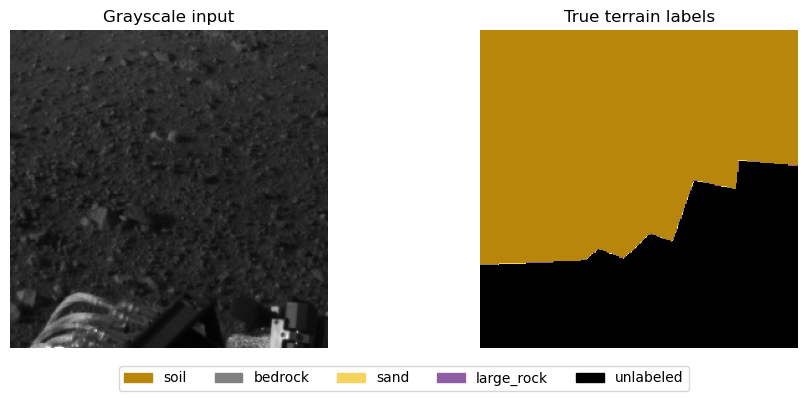

In [24]:
terrain_colors = ["#b8860b", "#808080", "#f4d35e", "#8f5ca6", "#000000"]
terrain_cmap = ListedColormap(terrain_colors)
terrain_norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), 5)

def display_mask(mask):
    # Use index 4 only for visualization of ignore label 255.
    shown = np.array(mask, copy=True)
    shown[shown == IGNORE_LABEL] = 4
    return shown

def show_prediction(image, target, prediction=None):
    columns = 2 if prediction is None else 3
    figure, axes = plt.subplots(1, columns, figsize=(5 * columns, 4))
    axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Grayscale input")
    axes[1].imshow(display_mask(target), cmap=terrain_cmap, norm=terrain_norm)
    axes[1].set_title("True terrain labels")
    if prediction is not None:
        axes[2].imshow(display_mask(prediction), cmap=terrain_cmap, norm=terrain_norm)
        axes[2].set_title("Predicted terrain labels")
    for axis in axes:
        axis.axis("off")
    labels = list(TERRAIN_CLASSES) + ["unlabeled"]
    legend = []
    for color, label in zip(terrain_colors, labels):
        legend.append(Patch(color=color, label=label))
    figure.legend(handles=legend, loc="lower center", ncol=5)
    figure.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

show_prediction(sample["image"][0].numpy(), sample["mask"].numpy())

Display the image and colored mask to check alignment. Black means unlabeled; display colors do not change training labels.

## 6. Random Forest training and validation

In [25]:
def sample_training_pixels(root, records, pixels_per_image=100, seed=360):
    """Sample labeled pixels without replacement from each training image."""
    if pixels_per_image < 1:
        raise ValueError("Pixels per image must be positive")
    rng = np.random.default_rng(seed)
    feature_samples = []
    label_samples = []

    for index, record in enumerate(records, 1):
        if record["split"] != "train":
            raise ValueError("Only training records may supply fitting pixels")
        image, mask = read_frozen_pair(root, record)
        labels = mask.ravel()
        labeled_indices = np.flatnonzero(labels != IGNORE_LABEL)
        if len(labeled_indices) == 0:
            raise ValueError(f"No labeled pixels: {record['mask']}")

        sample_size = min(pixels_per_image, len(labeled_indices))
        selected_indices = rng.choice(labeled_indices, size=sample_size, replace=False)
        features = pixel_features(image)
        feature_samples.append(features[selected_indices])
        label_samples.append(labels[selected_indices])
        if index % 100 == 0:
            print(f"Sampled {index}/{len(records)} training images", flush=True)

    if not feature_samples:
        raise ValueError("No training images supplied")
    # Each row has two features, and its target is one terrain class.
    training_features = np.concatenate(feature_samples, axis=0)
    training_labels = np.concatenate(label_samples).astype(np.int64)
    if set(np.unique(training_labels)) != {0, 1, 2, 3}:
        raise ValueError("The sampled training pixels must contain all four classes")
    return training_features, training_labels

Sample up to 100 labeled pixels per training image to keep fitting manageable. Exclude validation pixels from fitting.

In [26]:
def accuracy_counts(prediction, mask):
    """Count correct predictions and labeled pixels; label 255 is ignored."""
    if prediction.shape != mask.shape:
        raise ValueError("Prediction and mask dimensions must match")
    valid = mask != IGNORE_LABEL
    correct = int(np.count_nonzero(prediction[valid] == mask[valid]))
    total = int(np.count_nonzero(valid))
    return correct, total

Count correct and total labeled pixels to calculate accuracy over the full validation set. Ignore label 255.

In [27]:
rf_model = None
rf_results = None
if RUN_RF_TRAINING:
    if RF_MODEL_TO_LOAD is not None and RF_MODEL_TO_LOAD.exists():
        raise ValueError("A fitted forest exists. Reuse it; do not fit a duplicate.")
    if RF_OUTPUT.exists():
        raise FileExistsError("Choose a new RF_OUTPUT to preserve the previous run")
    RF_OUTPUT.mkdir(parents=True)
    features, targets = sample_training_pixels(data_root, training_records,
                                               PIXELS_PER_IMAGE, SEED)
    rf_model = build_baseline(SEED)
    rf_model.fit(features, targets)
    with (RF_OUTPUT / "model.pkl").open("wb") as stream:
        pickle.dump(rf_model, stream)
    rf_settings = {"seed": SEED, "pixels_per_training_image": PIXELS_PER_IMAGE,
                   "sampled_training_pixels": len(targets),
                   "model_parameters": rf_model.get_params(),
                   "sklearn_version": sklearn.__version__, "numpy_version": np.__version__,
                   "manifest_sha256": MANIFEST_HASH, "hyperparameter_tuning": False}
    (RF_OUTPUT / "settings.json").write_text(json.dumps(rf_settings, indent=2))
    del features, targets
elif RUN_RF_VALIDATION:
    if RF_MODEL_TO_LOAD is None or not RF_MODEL_TO_LOAD.exists():
        raise FileNotFoundError("Select your saved forest or enable fitting for a fresh run")
    rf_settings = json.loads((RF_MODEL_TO_LOAD.parent / "settings.json").read_text())
    if rf_settings["manifest_sha256"] != MANIFEST_HASH:
        raise ValueError("The forest was fitted with a different manifest")
    # Load only your own saved pickle files.
    cached_masks = set()
    full_progress = full_forest_folder / "validation_progress.json"
    if full_progress.exists():
        for saved in json.loads(full_progress.read_text()):
            cached_masks.add(saved["mask"])
    if validation_masks.issubset(cached_masks):
        print("All subset forest counts are cached; no model prediction is needed.")
    else:
        with RF_MODEL_TO_LOAD.open("rb") as stream:
            rf_model = pickle.load(stream)
else:
    print("Forest fitting and validation are off; existing saved results are read in Part 8.")

All subset forest counts are cached; no model prediction is needed.


Fit a new forest or load the saved one. Save the model and settings before validation, and protect existing runs.

In [28]:
def validate(model, root, records, output_directory):
    """Predict every validation image and save the first three examples."""
    total_correct = 0
    total_labeled = 0
    examples = []
    examples_directory = output_directory / "examples"
    examples_directory.mkdir(exist_ok=True)
    progress_path = output_directory / "validation_progress.json"
    completed = []
    if progress_path.exists():
        completed = json.loads(progress_path.read_text(encoding="utf-8"))
    if len(completed) > len(records):
        raise ValueError("Saved validation progress does not match this split")

    for index, record in enumerate(records, 1):
        if record["split"] != "val":
            raise ValueError("This run evaluates validation data only")
        if index <= len(completed):
            saved = completed[index - 1]
            if saved["mask"] != record["mask"]:
                raise ValueError("Saved validation progress has different membership")
            total_correct += saved["correct_pixels"]
            total_labeled += saved["labeled_pixels"]
            if index <= 3:
                examples.append(saved.get("example", {"source_mask": record["mask"]}))
            continue
        image, mask = read_frozen_pair(root, record)
        features = pixel_features(image)
        prediction = model.predict(features).reshape(mask.shape)
        correct, labeled = accuracy_counts(prediction, mask)
        total_correct += correct
        total_labeled += labeled

        # Save label PNGs, not plots. Values 0..3 are the predicted classes.
        # The true mask retains 255 for unlabeled pixels.
        if index <= 3:
            prefix = f"example_{index}"
            Image.fromarray(image).save(examples_directory / f"{prefix}_image.png")
            Image.fromarray(mask).save(examples_directory / f"{prefix}_true.png")
            Image.fromarray(prediction.astype(np.uint8)).save(
                examples_directory / f"{prefix}_prediction.png"
            )
            examples.append({"prefix": prefix, "source_image": record["image"],
                             "source_mask": record["mask"], "correct_pixels": correct,
                             "labeled_pixels": labeled})
        saved = {"mask": record["mask"], "correct_pixels": correct, "labeled_pixels": labeled}
        if index <= 3:
            saved["example"] = examples[-1]
        completed.append(saved)
        # Replace only after a complete write, keeping interrupted runs resumable.
        temporary_path = output_directory / "validation_progress.tmp"
        temporary_path.write_text(json.dumps(completed), encoding="utf-8")
        temporary_path.replace(progress_path)
        print(f"Validated {index}/{len(records)} images; accuracy so far: "
              f"{total_correct / total_labeled:.2%}", flush=True)

    if total_labeled == 0:
        raise ValueError("Validation contains no labeled pixels")
    return {"accuracy": total_correct / total_labeled,
            "correct_pixels": total_correct, "labeled_pixels": total_labeled,
            "images": len(records), "examples": examples}

Measure validation performance without fitting. Save example masks and per-image progress so interrupted validation can resume.

In [29]:
if RUN_RF_TRAINING:
    rf_run_folder = RF_OUTPUT
elif RF_MODEL_TO_LOAD is not None:
    rf_run_folder = RF_MODEL_TO_LOAD.parent
else:
    rf_run_folder = RF_OUTPUT
rf_validation_output = rf_run_folder / f"validation_subset_{VALIDATION_SIZE}"
progress_path = rf_validation_output / "validation_progress.json"
if RUN_RF_VALIDATION:
    rf_validation_output.mkdir(parents=True, exist_ok=True)
    if not progress_path.exists() and not RUN_RF_TRAINING:
        full_progress_path = full_forest_folder / "validation_progress.json"
        cache = {}
        if full_progress_path.exists():
            for saved in json.loads(full_progress_path.read_text()):
                cache[saved["mask"]] = saved
        # Only write the completed prefix of the selected images.
        completed_subset = []
        for record in validation_records:
            if record["mask"] not in cache:
                break
            completed_subset.append(cache[record["mask"]])
        progress_path.write_text(json.dumps(completed_subset))
        example_output = rf_validation_output / "examples"
        example_output.mkdir(exist_ok=True)
        for saved in completed_subset[:3]:
            if "example" in saved:
                prefix = saved["example"]["prefix"]
                for ending in ("image", "true", "prediction"):
                    name = f"{prefix}_{ending}.png"
                    source_path = full_forest_folder / "examples" / name
                    if source_path.exists():
                        shutil.copyfile(source_path, example_output / name)
if progress_path.exists():
    saved_progress = json.loads(progress_path.read_text())
    if len(saved_progress) > len(validation_records):
        raise ValueError("Saved subset progress is too long")
    for saved, record in zip(saved_progress, validation_records):
        if saved["mask"] != record["mask"]:
            raise ValueError("Saved subset progress uses different images")
    print(f"Subset forest counts available: {len(saved_progress)}/{len(validation_records)}")
print("Subset validation folder:", rf_validation_output)

Subset forest counts available: 100/100
Subset validation folder: D:\PROJECTS_ADA\APS360\Terrain Segmentation\outputs\random_forest_run1\validation_subset_100


Reuse completed forest counts in a separate subset folder. The full-run progress and original examples are not overwritten.

Random Forest: example_1


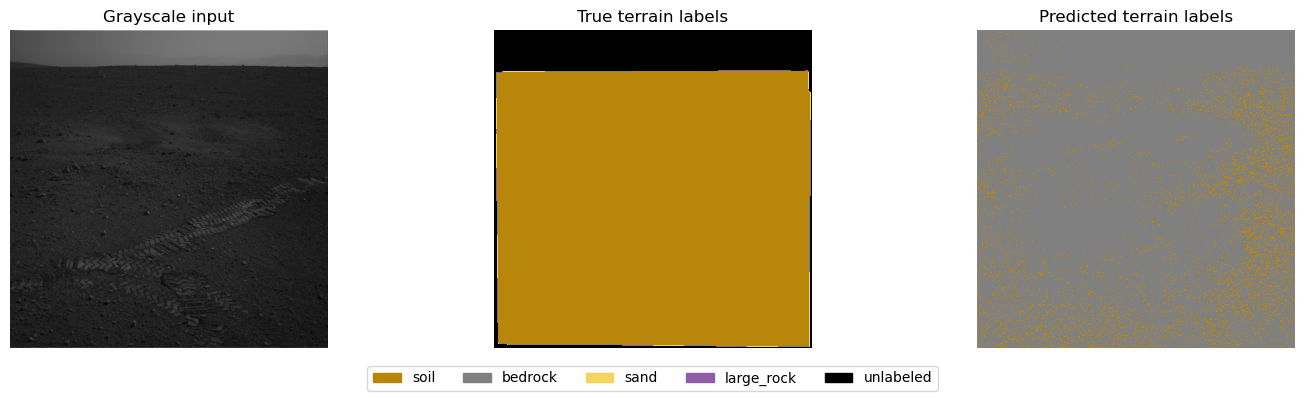

This image's labeled-pixel accuracy: 29.26%
Random Forest: example_2


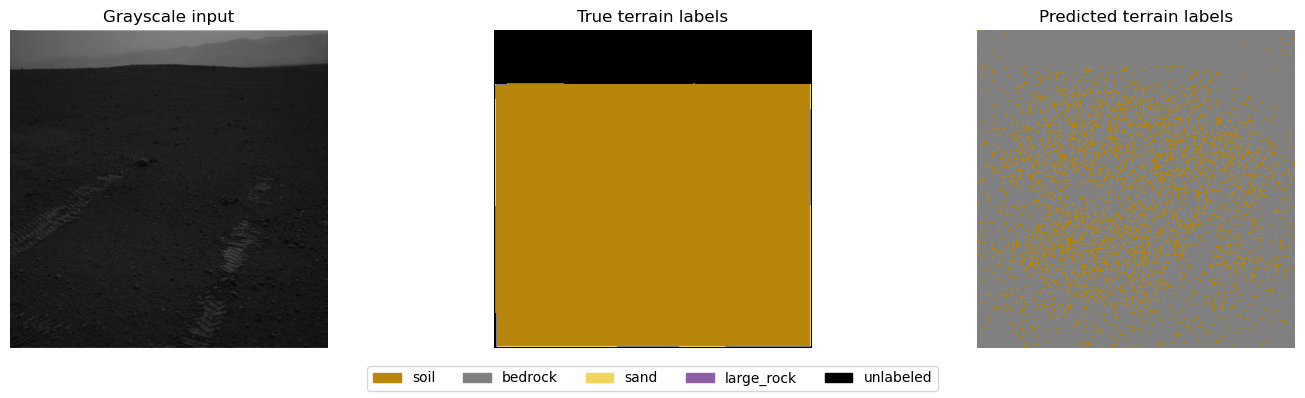

This image's labeled-pixel accuracy: 35.36%
Random Forest: example_3


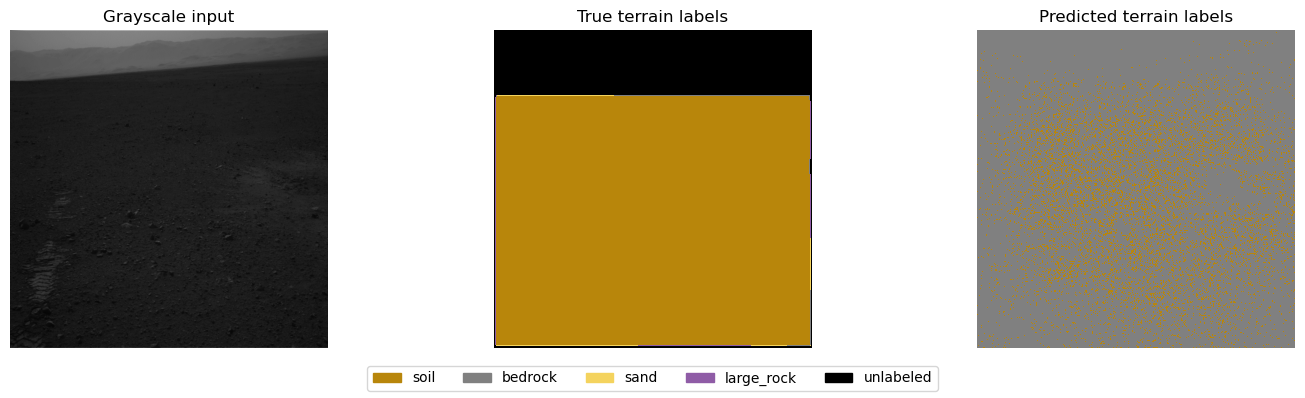

This image's labeled-pixel accuracy: 34.87%


In [30]:
example_folder = rf_validation_output / "examples"
saved_images = sorted(example_folder.glob("example_*_image.png"))
if not saved_images:
    print("No saved forest examples yet. Validation saves the first three.")
for image_path in saved_images[:3]:
    prefix = image_path.stem.removesuffix("_image")
    with Image.open(image_path) as source:
        image = np.array(source.convert("L"), dtype=np.float32) / 255.0
    with Image.open(example_folder / f"{prefix}_true.png") as source:
        true_mask = np.array(source)
    with Image.open(example_folder / f"{prefix}_prediction.png") as source:
        predicted_mask = np.array(source)
    print("Random Forest:", prefix)
    show_prediction(image, true_mask, predicted_mask)
    correct, total = accuracy_counts(predicted_mask, true_mask)
    if total > 0:
        print(f"This image's labeled-pixel accuracy: {correct / total:.2%}")

Display the first three saved forest predictions without fitting or predicting again. These examples do not represent every terrain class.

In [31]:
if RUN_RF_VALIDATION:
    rf_validation_output.mkdir(parents=True, exist_ok=True)
    result_path = rf_validation_output / "validation.json"
    provenance_path = rf_validation_output / "source.json"
    model_path = RF_OUTPUT / "model.pkl" if RUN_RF_TRAINING else RF_MODEL_TO_LOAD
    provenance = {"manifest_sha256": MANIFEST_HASH,
                  "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
                  "validation_subset_sha256": SUBSET_HASH}
    if provenance_path.exists():
        if json.loads(provenance_path.read_text()) != provenance:
            raise ValueError("Progress belongs to a different model or manifest")
    else:
        # The original run predates source.json. Its training manifest was
        # checked when loading the model; saved image order was checked above.
        provenance_path.write_text(json.dumps(provenance, indent=2))
    if result_path.exists():
        rf_results = json.loads(result_path.read_text())
    else:
        rf_results = validate(rf_model, data_root, validation_records, rf_validation_output)
        rf_results["validation_subset_sha256"] = SUBSET_HASH
        rf_results["scope"] = "fixed validation subset"
        result_path.write_text(json.dumps(rf_results, indent=2))
    print("Forest subset accuracy:", f"{rf_results['accuracy']:.2%}")
else:
    print("Forest validation is off. Enable RUN_RF_VALIDATION to evaluate the fixed subset.")

Forest subset accuracy: 35.24%


Continue validation only when enabled. Preserve completed counts, save new progress after each image, and write a final score when every validation image is checked.

## 7. CNN training and validation

In [32]:
def run_epoch(model, loader, device, optimizer=None):
    """Fit when an optimizer is supplied; otherwise only measure validation."""
    training = optimizer is not None
    model.train(training)
    # Sum losses so epoch averages are weighted by labeled-pixel counts.
    criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_LABEL, reduction="sum")
    total_loss = 0.0
    total_correct = 0
    total_labeled = 0
    skipped_batches = 0

    for batch_number, batch in enumerate(loader, 1):
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)
        valid = masks != IGNORE_LABEL
        labeled_count = int(valid.sum().item())
        # Some validation tiles can contain no annotations at all.
        if labeled_count == 0:
            skipped_batches += 1
            continue

        if training:
            optimizer.zero_grad()
        # Validation should not build the gradient information used for fitting.
        with torch.set_grad_enabled(training):
            scores = model(images)
            if not torch.isfinite(scores).all():
                raise ValueError("The CNN produced nonfinite scores")
            loss_sum = criterion(scores, masks)
            loss = loss_sum / labeled_count
            if not torch.isfinite(loss):
                raise ValueError("The CNN loss is nonfinite")
            if training:
                loss.backward()
                optimizer.step()

        # Dimension 1 contains the four class scores.
        predictions = scores.argmax(dim=1)
        total_correct += int(((predictions == masks) & valid).sum().item())
        total_labeled += labeled_count
        total_loss += float(loss_sum.detach().item())
        if batch_number % 50 == 0:
            print(f"Batch {batch_number}/{len(loader)}; "
                  f"accuracy so far: {total_correct / total_labeled:.2%}", flush=True)

    if total_labeled == 0:
        raise ValueError("No labeled pixels were processed")
    return {"loss": total_loss / total_labeled,
            "accuracy": total_correct / total_labeled,
            "correct_pixels": total_correct, "labeled_pixels": total_labeled,
            "all_ignore_batches_skipped": skipped_batches}

Update weights only during training. During validation, measure loss and accuracy without gradients. Ignore label 255 and skip all-unlabeled batches.

In [ ]:
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
cnn_history = []
cnn_ready = False
cnn_subset_results = None

if RUN_CNN_TRAINING:
    if CNN_OUTPUT.exists():
        raise FileExistsError("Choose a new CNN_OUTPUT to preserve existing checkpoints")
    CNN_OUTPUT.mkdir(parents=True)
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    cnn = TerrainCNN().to(device)
    optimizer = torch.optim.Adam(cnn.parameters(), lr=LEARNING_RATE)
    cnn_settings = {"seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
                    "learning_rate": LEARNING_RATE, "optimizer": "Adam",
                    "loss": "Unweighted cross entropy; ignore 255",
                    "metric": "Labeled-pixel accuracy", "device": str(device),
                    "torch_version": str(torch.__version__),
                    "parameters": sum(p.numel() for p in cnn.parameters()),
                    "manifest_sha256": MANIFEST_HASH,
                    "validation_subset_sha256": SUBSET_HASH,
                    "validation_images": len(validation_records)}
    (CNN_OUTPUT / "settings.json").write_text(json.dumps(cnn_settings, indent=2))
    best_accuracy = -1.0
    for epoch in range(EPOCHS):
        print(f"Epoch {epoch + 1}/{EPOCHS}")
        train_data.set_epoch(epoch)
        training = run_epoch(cnn, train_loader, device, optimizer)
        checkpoint = {"epoch": epoch + 1, "model": cnn.state_dict(),
                      "optimizer": optimizer.state_dict(), "settings": cnn_settings}
        torch.save(checkpoint, CNN_OUTPUT / "last.pt")
        validation = run_epoch(cnn, val_loader, device)
        cnn_history.append({"epoch": epoch + 1, "train": training, "val": validation, "validation_subset_sha256": SUBSET_HASH})
        (CNN_OUTPUT / "history.json").write_text(json.dumps(cnn_history, indent=2))
        if validation["accuracy"] > best_accuracy:
            best_accuracy = validation["accuracy"]
            torch.save(checkpoint, CNN_OUTPUT / "best.pt")
        print("Training:", training)
        print("Validation:", validation)
    cnn_ready = True
    cnn_subset_results = cnn_history[-1]["val"].copy()
elif CNN_MODEL_TO_LOAD is not None and CNN_MODEL_TO_LOAD.exists():
    checkpoint = torch.load(CNN_MODEL_TO_LOAD, map_location="cpu", weights_only=True)
    if checkpoint["settings"]["manifest_sha256"] != MANIFEST_HASH:
        raise ValueError("The CNN checkpoint uses a different frozen manifest")
    cnn.load_state_dict(checkpoint["model"])
    cnn_ready = True
    print("Loaded CNN checkpoint from epoch", checkpoint["epoch"])
else:
    print("No trained CNN loaded. Enable training for a fresh experiment.")

Batch the crops, train the CNN and validate after each epoch. Save the settings, history, last checkpoint and best-validation checkpoint.

In [34]:
if cnn_ready:
    if RUN_CNN_TRAINING:
        cnn_model_path = CNN_OUTPUT / "last.pt"
    else:
        cnn_model_path = CNN_MODEL_TO_LOAD
    cnn_validation_folder = cnn_model_path.parent / f"validation_subset_{VALIDATION_SIZE}"
    cnn_result_path = cnn_validation_folder / "validation.json"
    cnn_source = {"manifest_sha256": MANIFEST_HASH,
                  "validation_subset_sha256": SUBSET_HASH,
                  "model_sha256": hashlib.sha256(cnn_model_path.read_bytes()).hexdigest()}
    if cnn_result_path.exists():
        saved_result = json.loads(cnn_result_path.read_text())
        for key, value in cnn_source.items():
            if saved_result[key] != value:
                raise ValueError("Saved CNN subset result belongs to different inputs")
        cnn_subset_results = saved_result
    elif RUN_CNN_VALIDATION or RUN_CNN_TRAINING:
        if not RUN_CNN_TRAINING:
            cnn_subset_results = run_epoch(cnn, val_loader, device)
        cnn_subset_results.update(cnn_source)
        cnn_subset_results["images"] = len(validation_records)
        cnn_subset_results["scope"] = "fixed validation subset"
        cnn_validation_folder.mkdir(exist_ok=True)
        cnn_result_path.write_text(json.dumps(cnn_subset_results, indent=2))
    if cnn_subset_results is not None:
        print("CNN subset accuracy:", f"{cnn_subset_results['accuracy']:.2%}")
    else:
        print("Enable RUN_CNN_VALIDATION to measure this checkpoint on the fixed subset.")

Batch 50/200; accuracy so far: 28.49%
Batch 100/200; accuracy so far: 25.17%
Batch 150/200; accuracy so far: 20.04%
Batch 200/200; accuracy so far: 28.54%
CNN subset accuracy: 28.54%


Evaluate the saved CNN on the same selected images as the forest. Cache the subset result separately; do not substitute the older full-validation accuracy.

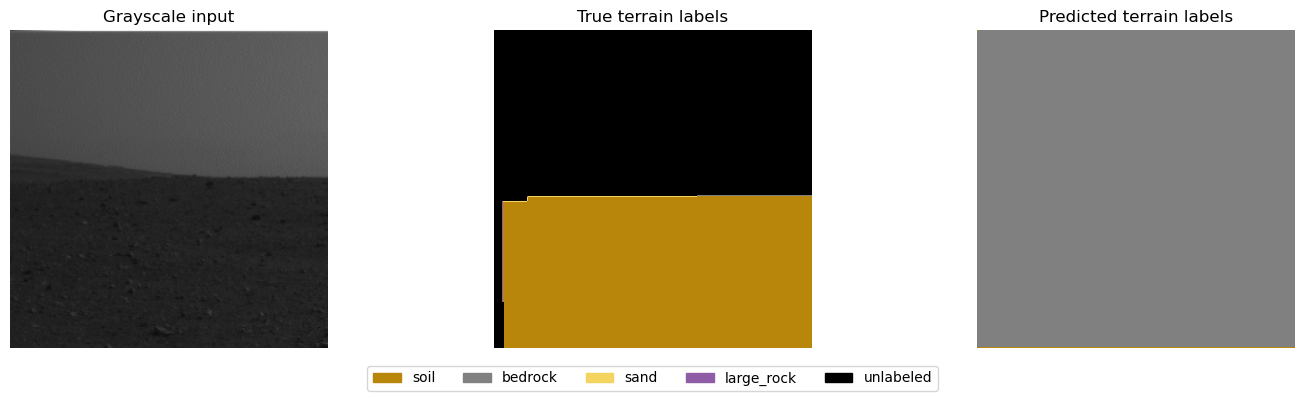

soil predicted labeled pixels: 248
bedrock predicted labeled pixels: 30105
sand predicted labeled pixels: 0
large_rock predicted labeled pixels: 0
This tile's labeled-pixel accuracy: 0.82%


In [35]:
VALIDATION_TILE_INDEX = 0
if cnn_ready:
    validation_sample = val_data[VALIDATION_TILE_INDEX]
    cnn.eval()
    with torch.no_grad():
        image_batch = validation_sample["image"].unsqueeze(0).to(device)
        scores = cnn(image_batch)
        predicted_mask = scores.argmax(dim=1)[0].cpu().numpy()
    true_mask = validation_sample["mask"].numpy()
    valid = true_mask != IGNORE_LABEL
    show_prediction(validation_sample["image"][0].numpy(), true_mask, predicted_mask)
    for class_id, class_name in enumerate(TERRAIN_CLASSES):
        print(class_name, "predicted labeled pixels:", int(np.count_nonzero(predicted_mask[valid] == class_id)))
    correct, total = accuracy_counts(predicted_mask, true_mask)
    if total > 0:
        print("This tile's labeled-pixel accuracy:", f"{correct / total:.2%}")
    else:
        print("This tile has no labeled pixels; choose another tile.")
else:
    print("Load or train a CNN before inspecting predictions.")

Compare one tile's true and predicted masks to inspect terrain errors. Class counts can reveal predictions dominated by one terrain type.

## 8. Results comparison

In [36]:
if rf_results is None:
    saved_rf_result = rf_validation_output / "validation.json"
    if saved_rf_result.exists():
        rf_results = json.loads(saved_rf_result.read_text())
if rf_results is not None:
    if rf_results["validation_subset_sha256"] != SUBSET_HASH:
        raise ValueError("Forest result uses a different subset")
    assert rf_results["labeled_pixels"] == validation_subset["labeled_pixels"]
    print("Random Forest subset accuracy:", f"{rf_results['accuracy']:.2%}")
else:
    print("Forest subset result is not ready.")
if cnn_subset_results is not None:
    assert cnn_subset_results["labeled_pixels"] == validation_subset["labeled_pixels"]
    print("CNN subset accuracy:", f"{cnn_subset_results['accuracy']:.2%}")
else:
    print("CNN subset result is not ready.")
class_counts = validation_subset["pixels_by_class"]
bedrock_reference = class_counts["bedrock"] / sum(class_counts.values())
print("Always-bedrock subset reference:", f"{bedrock_reference:.2%}")
print("Scope:", len(validation_records), "fixed images; not the full validation set.")

Random Forest subset accuracy: 35.24%
CNN subset accuracy: 28.54%
Always-bedrock subset reference: 28.48%
Scope: 100 fixed images; not the full validation set.


Compare only scores measured on the same saved images and labeled pixels. The majority-class reference uses this subset too.

## Sources

### Methods, code and contribution

- AI4MARS images and annotations are external data [1].
- The baseline uses scikit-learn's `RandomForestClassifier`, not a new forest implementation [2,3]. Pixel intensity and local mean are standard image features; their preparation code was written for this project.
- The CNN specifies its own small layer configuration using standard PyTorch operations [4]. Fully convolutional segmentation and encoder-decoder ideas are established methods [5,6]. The current model is not a full U-Net implementation and does not import a completed external CNN or external pretrained weights. Its weights were initially trained from random initialization; subsequent notebook runs load this project's own checkpoints.
- Adam [7], cross-entropy, pooling, bilinear upsampling, flips and brightness changes are established methods, not original algorithmic contributions. Their library implementations are provided by PyTorch and NumPy.
- Project-specific work consists of the compact CNN configuration, label-aware preparation, command-based splitting following TA feedback, and a shared-subset forest/CNN experiment. These are an application and implementation of established methods, not a claim of a newly invented architecture. The skip-connection comparison remains planned work.
- Notebook organization follows the provided APS360 tutorial structure [8].

Codex helped generate code at some stages of this project.

### References

[1] Swan et al. (2021), [AI4MARS: A Dataset for Terrain-Aware Autonomous Driving on Mars](https://openaccess.thecvf.com/content/CVPR2021W/AI4Space/html/Swan_AI4MARS_A_Dataset_for_Terrain-Aware_Autonomous_Driving_on_Mars_CVPRW_2021_paper.html).

[2] Breiman (2001), [Random Forests](https://doi.org/10.1023/A:1010933404324).

[3] Pedregosa et al. (2011), [Scikit-learn: Machine Learning in Python](https://www.jmlr.org/papers/v12/pedregosa11a.html); [RandomForestClassifier implementation documentation](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.RandomForestClassifier.html). The saved baseline used scikit-learn 1.5.1.

[4] Paszke et al. (2019), [PyTorch: An Imperative Style, High-Performance Deep Learning Library](https://proceedings.neurips.cc/paper_files/paper/2019/hash/bdbca288fee7f92f2bfa9f7012727740-Abstract.html).

[5] Long, Shelhamer and Darrell (2014 preprint; CVPR 2015), [Fully Convolutional Networks for Semantic Segmentation](https://arxiv.org/abs/1411.4038).

[6] Ronneberger, Fischer and Brox (2015), [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597).

[7] Kingma and Ba (ICLR 2015), [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980).

[8] APS360 course material, *Tutorial 4: Convolutional Neural Networks and Transfer Learning* (provided course notebook; organization and teaching structure).